In [1]:
!pip install dtreeviz

In [2]:
import graphviz.backend as bs
from sklearn.datasets import *
from dtreeviz.trees import *
from IPython.display import Image, display_svg, SVG

In [12]:
from sklearn.tree import DecisionTreeClassifier
clas = DecisionTreeClassifier(max_depth=2)
iris = load_iris()

X_train = iris.data
y_train = iris.target
clas.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

#### SK Learn's plot_tree function

[Text(0.4, 0.8333333333333334, 'x[2] <= 2.45\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[3] <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.168\nsamples = 54\nvalue = [0, 49, 5]'),
 Text(0.8, 0.16666666666666666, 'gini = 0.043\nsamples = 46\nvalue = [0, 1, 45]')]

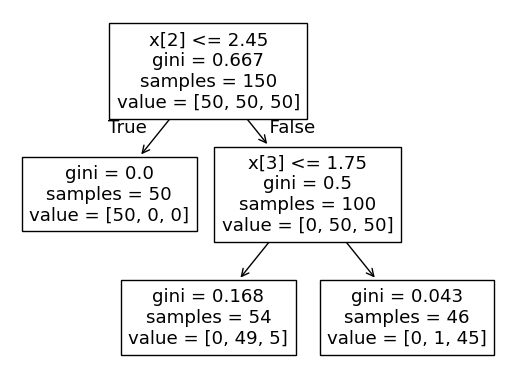

In [4]:
from sklearn.tree import plot_tree
plot_tree(clas)

### 1. Classification

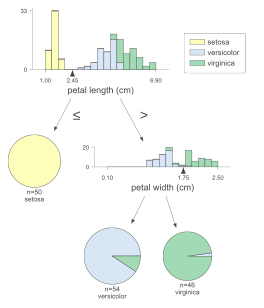

In [7]:
import dtreeviz
viz_model = dtreeviz.model(clas,
              X_train,
              y_train,
              feature_names = iris.feature_names,
              class_names = ['setosa','versicolor','virginica'])
viz_model.view()

A very refined Tree is given here

We know the exact split , features upon which split was performed and many other information

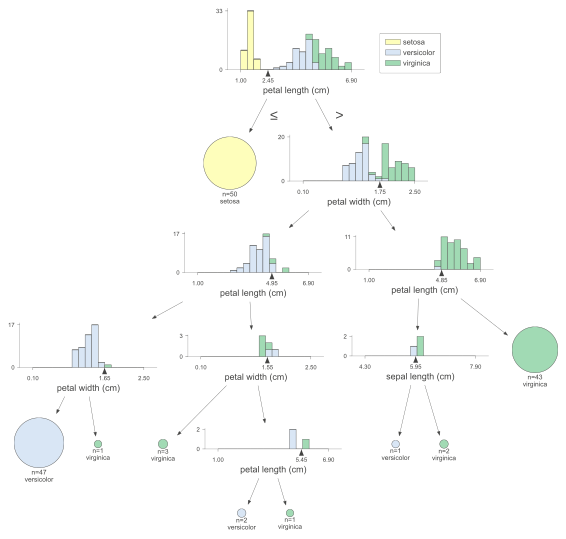

In [9]:
clas = DecisionTreeClassifier()
clas.fit(X_train , y_train)
viz_model = dtreeviz.model(clas,
              X_train,
              y_train,
              feature_names = iris.feature_names,
              class_names = ['setosa','versicolor','virginica'])
viz_model.view()

### 2. Regression

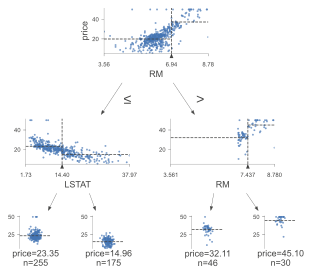

In [11]:
from sklearn.tree import DecisionTreeRegressor
regr = DecisionTreeRegressor(max_depth=2)

data_url = "http://lib.stat.cmu.edu/datasets/boston"

raw_df = pd.read_csv(
    data_url,
    sep=r"\s+",
    skiprows=22,
    header=None
)

X_train = np.hstack([
    raw_df.values[::2, :],
    raw_df.values[1::2, :2]
])

y_train = raw_df.values[1::2, 2]

columns = [
    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX',
    'RM', 'AGE', 'DIS', 'RAD', 'TAX',
    'PTRATIO', 'B', 'LSTAT'
]

df = pd.DataFrame(X_train, columns=columns)
df['MEDV'] = y_train

regr.fit(X_train,y_train)

viz_model = dtreeviz.model(regr,
                    X_train,
                    y_train,
                    target_name='price',
                    feature_names=[
                    'CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX',
                    'RM', 'AGE', 'DIS', 'RAD', 'TAX',
                    'PTRATIO', 'B', 'LSTAT'
                    ])
viz_model.view()

### 3. Horizontal Decision Tree

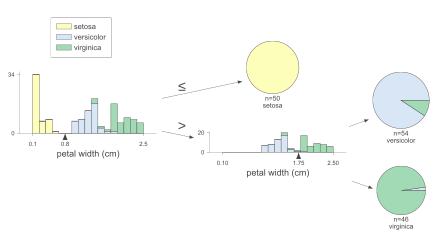

In [14]:
viz_model = dtreeviz.model(clas,
              X_train,
              y_train,
              feature_names = iris.feature_names,
              class_names = ['setosa','versicolor','virginica'])
viz_model.view(orientation='LR')

### 4. Show Prediction Path

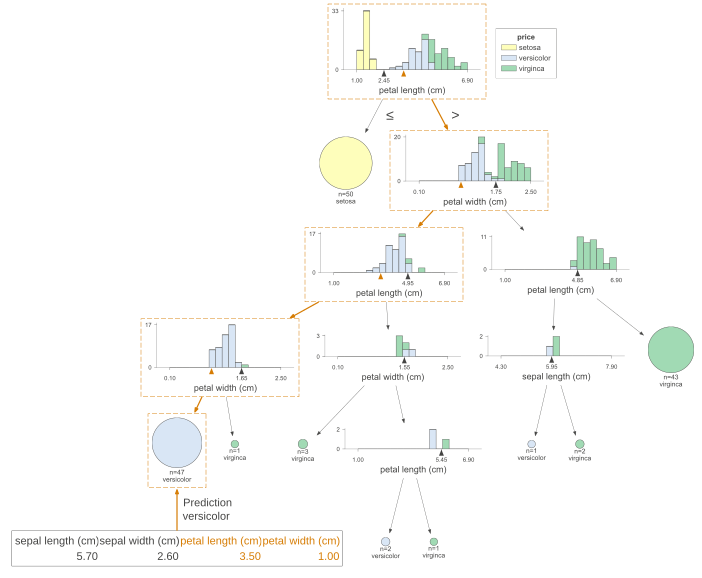

In [21]:
## See the predicition path of a random point
clas = DecisionTreeClassifier()
iris = load_iris()

X_train = iris.data
y_train = iris.target
clas.fit(X_train,y_train)

X = iris.data[np.random.randint(0,len(iris.data)),:]

viz = dtreeviz.model(clas,
                    X_train,
                    y_train,
                    target_name='price',
                    feature_names=iris.feature_names,
                    class_names=['setosa','versicolor','virginca'])
viz.view(x=X)

### 5. Show Random Node

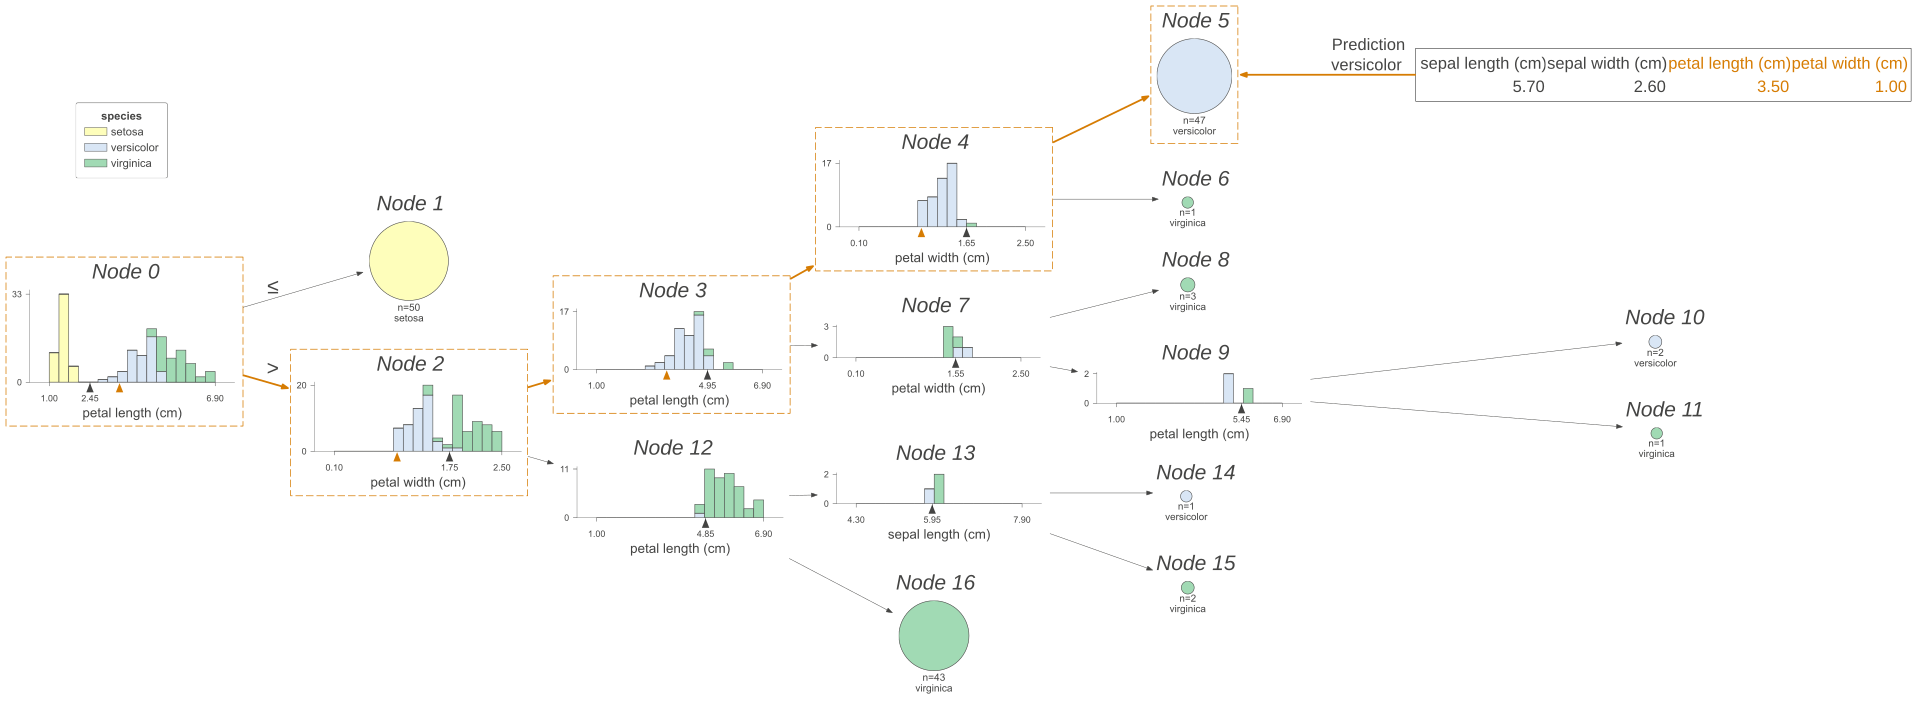

In [24]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='species',
    feature_names=iris.feature_names,
    class_names=['setosa', 'versicolor', 'virginica']
)

viz.view(
    x=X,
    orientation='LR',
    show_node_labels=True,
    scale=1.5
)

### 6. Without any Graphs

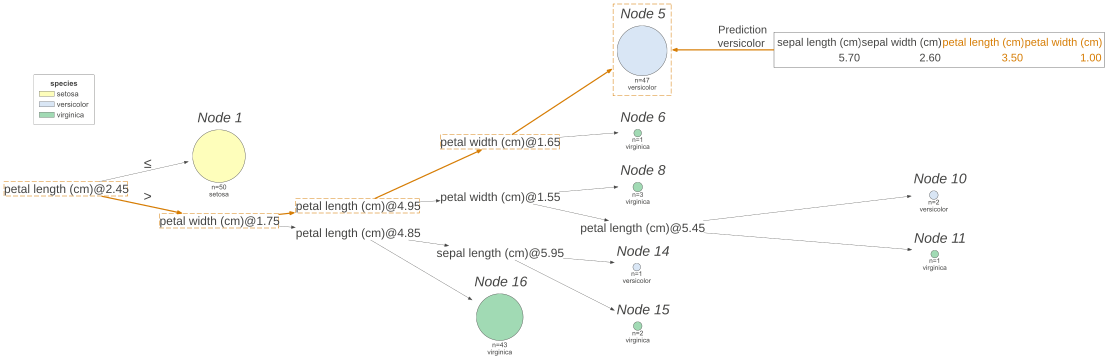

In [25]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='species',
    feature_names=iris.feature_names,
    class_names=['setosa', 'versicolor', 'virginica']
)

viz.view(
    x=X,
    orientation='LR',
    show_node_labels=True,
    scale=1.,
    fancy=False
)

### 7. Show just Prediction Path and nothing else

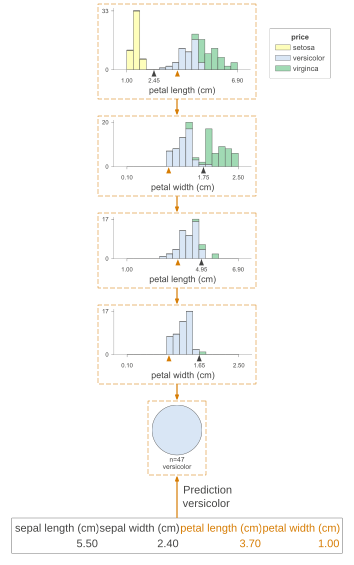

In [26]:
clas = DecisionTreeClassifier()
iris = load_iris()

X_train = iris.data
y_train = iris.target
clas.fit(X_train,y_train)

X = iris.data[np.random.randint(0,len(iris.data)),:]

viz = dtreeviz.model(clas,
                    X_train,
                    y_train,
                    target_name='price',
                    feature_names=iris.feature_names,
                    class_names=['setosa','versicolor','virginca'])
viz.view(x=X,show_just_path=True)

### 8. Prediction Path in plain English

In [28]:
viz = dtreeviz.model(
    clas,
    X_train=X_train,
    y_train=y_train,
    target_name='species',
    feature_names=iris.feature_names,
    class_names=['setosa', 'versicolor', 'virginica']
)
print(viz.explain_prediction_path(X))

2.45 <= petal length (cm)  < 4.95
petal width (cm) < 1.65



### 9. Feature Importance

In [31]:
print(viz.explain_prediction_path(X))

2.45 <= petal length (cm)  < 4.95
petal width (cm) < 1.65



### 10. Univariate Regression